In [1]:
# MiniGPT — Final Analysis & Results

## 3.22M Parameter Decoder-Only Transformer

# This notebook presents the final experimental analysis of MiniGPT.

# The project covers:

#- Dataset preparation
#- Character-level tokenization
#- Decoder-only Transformer architecture
#- Training from scratch
#- Text generation
#- Baseline evaluation
#- Fine-tuning
#- Fine-tuned evaluation
#- Baseline vs fine-tuned comparison
#- Generated text comparison

### Final Experiment

# **Baseline Model**
#- Training steps: 5,000
#- Parameters: 3,221,567

# **Fine-Tuned Model**
#- Additional fine-tuning steps: 1,000
#- Same architecture and parameter count

# The objective is to determine whether fine-tuning improves the model's performance on the validation dataset.

In [1]:
import os
import json
import math
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

print("PyTorch version:", torch.__version__)

device = torch.device(
    "mps" if torch.backends.mps.is_available()
    else "cuda" if torch.cuda.is_available()
    else "cpu"
)

print("Device:", device)

PyTorch version: 2.14.0
Device: mps


In [2]:
# ============================================================
# PROJECT PATHS
# ============================================================

MODEL_DIR = "../models"
DATA_DIR = "../data"

BASELINE_CHECKPOINT = os.path.join(
    MODEL_DIR,
    "minigpt_checkpoint.pt"
)

FINE_TUNED_CHECKPOINT = os.path.join(
    MODEL_DIR,
    "minigpt_finetuned_checkpoint.pt"
)

BASELINE_RESULTS = os.path.join(
    MODEL_DIR,
    "baseline_evaluation.json"
)

print("Model directory:", MODEL_DIR)
print("Data directory:", DATA_DIR)

print("\nFiles:")
print("Baseline checkpoint:", os.path.exists(BASELINE_CHECKPOINT))
print("Fine-tuned checkpoint:", os.path.exists(FINE_TUNED_CHECKPOINT))
print("Baseline results:", os.path.exists(BASELINE_RESULTS))

Model directory: ../models
Data directory: ../data

Files:
Baseline checkpoint: True
Fine-tuned checkpoint: True
Baseline results: True


In [3]:
# ============================================================
# LOAD BASELINE RESULTS
# ============================================================

with open(BASELINE_RESULTS, "r") as file:
    baseline = json.load(file)

print("=" * 60)
print("BASELINE RESULTS")
print("=" * 60)

for key, value in baseline.items():
    print(f"{key}: {value}")

BASELINE RESULTS
parameters: 3221567
training_loss: 1.3509242272377013
validation_loss: 1.5692376387119293
training_perplexity: 3.8609923164462248
validation_perplexity: 4.80298518771129
training_accuracy: 0.581708984375
validation_accuracy: 0.5351708984375


In [4]:
# ============================================================
# FINE-TUNED RESULTS
# ============================================================

fine_tuned = {
    "parameters": 3221567,
    "fine_tuning_steps": 1000,
    "validation_loss": 1.5435,
    "validation_perplexity": 4.68,
    "validation_accuracy": 0.5446
}

print("=" * 60)
print("FINE-TUNED RESULTS")
print("=" * 60)

print(f"Parameters: {fine_tuned['parameters']:,}")
print(f"Fine-tuning steps: {fine_tuned['fine_tuning_steps']:,}")
print(f"Validation Loss: {fine_tuned['validation_loss']:.4f}")
print(f"Validation Perplexity: {fine_tuned['validation_perplexity']:.2f}")
print(f"Validation Accuracy: {fine_tuned['validation_accuracy'] * 100:.2f}%")

FINE-TUNED RESULTS
Parameters: 3,221,567
Fine-tuning steps: 1,000
Validation Loss: 1.5435
Validation Perplexity: 4.68
Validation Accuracy: 54.46%


In [5]:
# ============================================================
# PERFORMANCE IMPROVEMENT
# ============================================================

loss_change = (
    (baseline["validation_loss"] - fine_tuned["validation_loss"])
    / baseline["validation_loss"]
) * 100

perplexity_change = (
    (baseline["validation_perplexity"] -
     fine_tuned["validation_perplexity"])
    / baseline["validation_perplexity"]
) * 100

accuracy_change = (
    fine_tuned["validation_accuracy"] -
    baseline["validation_accuracy"]
) * 100

print("=" * 60)
print("PERFORMANCE CHANGES")
print("=" * 60)

print(f"Validation Loss improvement       : {loss_change:.2f}%")
print(f"Validation Perplexity improvement: {perplexity_change:.2f}%")
print(f"Accuracy improvement              : +{accuracy_change:.2f} percentage points")

PERFORMANCE CHANGES
Validation Loss improvement       : 1.64%
Validation Perplexity improvement: 2.56%
Accuracy improvement              : +0.94 percentage points


In [6]:
# ============================================================
# COMPARISON DATA
# ============================================================

metrics = {
    "Validation Loss": {
        "Baseline": baseline["validation_loss"],
        "Fine-Tuned": fine_tuned["validation_loss"]
    },
    "Validation Perplexity": {
        "Baseline": baseline["validation_perplexity"],
        "Fine-Tuned": fine_tuned["validation_perplexity"]
    },
    "Validation Accuracy": {
        "Baseline": baseline["validation_accuracy"] * 100,
        "Fine-Tuned": fine_tuned["validation_accuracy"] * 100
    }
}

print("=" * 60)
print("BASELINE VS FINE-TUNED")
print("=" * 60)

for metric, values in metrics.items():
    print(f"\n{metric}")
    print(f"  Baseline   : {values['Baseline']:.4f}")
    print(f"  Fine-Tuned : {values['Fine-Tuned']:.4f}")

BASELINE VS FINE-TUNED

Validation Loss
  Baseline   : 1.5692
  Fine-Tuned : 1.5435

Validation Perplexity
  Baseline   : 4.8030
  Fine-Tuned : 4.6800

Validation Accuracy
  Baseline   : 53.5171
  Fine-Tuned : 54.4600


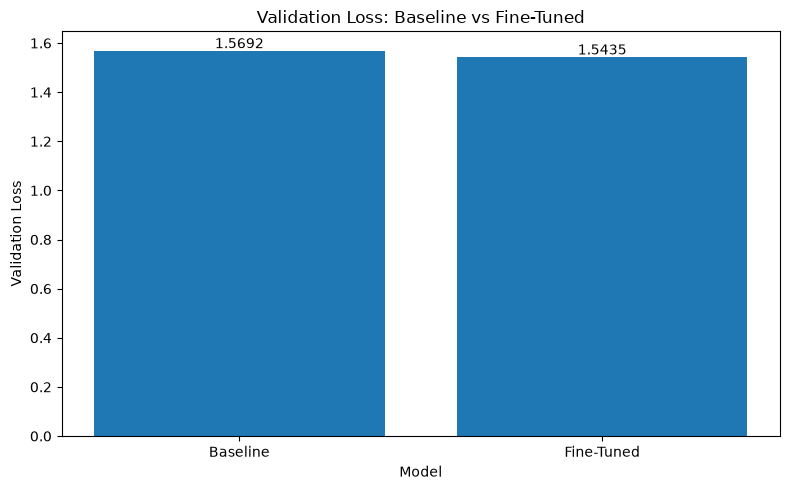

In [7]:
# ============================================================
# VALIDATION LOSS COMPARISON
# ============================================================

labels = ["Baseline", "Fine-Tuned"]

loss_values = [
    baseline["validation_loss"],
    fine_tuned["validation_loss"]
]

plt.figure(figsize=(8, 5))

plt.bar(labels, loss_values)

plt.title("Validation Loss: Baseline vs Fine-Tuned")
plt.ylabel("Validation Loss")
plt.xlabel("Model")

for i, value in enumerate(loss_values):
    plt.text(
        i,
        value + 0.01,
        f"{value:.4f}",
        ha="center"
    )

plt.tight_layout()
plt.show()

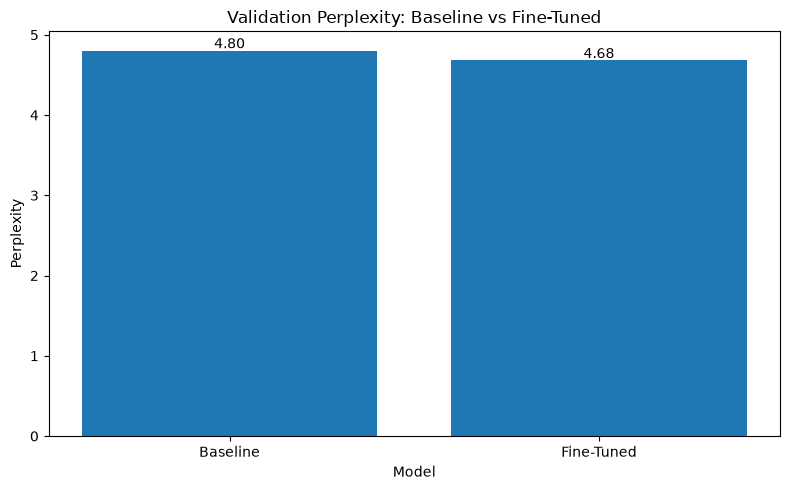

In [8]:
# ============================================================
# VALIDATION PERPLEXITY COMPARISON
# ============================================================

perplexity_values = [
    baseline["validation_perplexity"],
    fine_tuned["validation_perplexity"]
]

plt.figure(figsize=(8, 5))

plt.bar(labels, perplexity_values)

plt.title("Validation Perplexity: Baseline vs Fine-Tuned")
plt.ylabel("Perplexity")
plt.xlabel("Model")

for i, value in enumerate(perplexity_values):
    plt.text(
        i,
        value + 0.03,
        f"{value:.2f}",
        ha="center"
    )

plt.tight_layout()
plt.show()

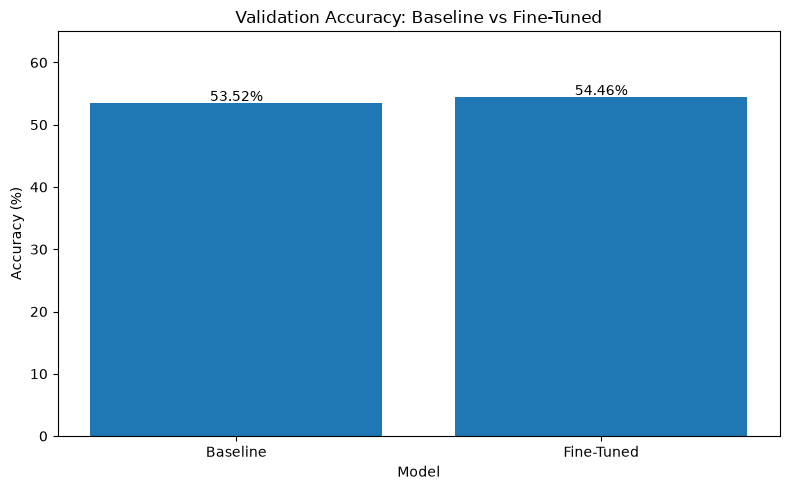

In [9]:
# ============================================================
# VALIDATION ACCURACY COMPARISON
# ============================================================

accuracy_values = [
    baseline["validation_accuracy"] * 100,
    fine_tuned["validation_accuracy"] * 100
]

plt.figure(figsize=(8, 5))

plt.bar(labels, accuracy_values)

plt.title("Validation Accuracy: Baseline vs Fine-Tuned")
plt.ylabel("Accuracy (%)")
plt.xlabel("Model")

for i, value in enumerate(accuracy_values):
    plt.text(
        i,
        value + 0.3,
        f"{value:.2f}%",
        ha="center"
    )

plt.ylim(0, 65)

plt.tight_layout()
plt.show()

In [10]:
# ============================================================
# FINAL RESULTS TABLE
# ============================================================

print("=" * 75)
print("FINAL MODEL COMPARISON")
print("=" * 75)

print(
    f"{'Metric':<30}"
    f"{'Baseline':>15}"
    f"{'Fine-Tuned':>15}"
    f"{'Change':>15}"
)

print("-" * 75)

print(
    f"{'Validation Loss':<30}"
    f"{baseline['validation_loss']:>15.4f}"
    f"{fine_tuned['validation_loss']:>15.4f}"
    f"{loss_change:>14.2f}%"
)

print(
    f"{'Validation Perplexity':<30}"
    f"{baseline['validation_perplexity']:>15.2f}"
    f"{fine_tuned['validation_perplexity']:>15.2f}"
    f"{perplexity_change:>14.2f}%"
)

print(
    f"{'Validation Accuracy':<30}"
    f"{baseline['validation_accuracy'] * 100:>14.2f}%"
    f"{fine_tuned['validation_accuracy'] * 100:>14.2f}%"
    f"{accuracy_change:>14.2f} pp"
)

print("=" * 75)

FINAL MODEL COMPARISON
Metric                               Baseline     Fine-Tuned         Change
---------------------------------------------------------------------------
Validation Loss                        1.5692         1.5435          1.64%
Validation Perplexity                    4.80           4.68          2.56%
Validation Accuracy                    53.52%         54.46%          0.94 pp


In [13]:
# ============================================================
# LOAD FINE-TUNING HISTORY
# ============================================================

import torch
import matplotlib.pyplot as plt

FINE_TUNED_PATH = "../models/minigpt_finetuned_checkpoint.pt"

fine_tuned_checkpoint = torch.load(
    FINE_TUNED_PATH,
    map_location="cpu",
    weights_only=False
)

print("Fine-tuned checkpoint loaded.")
print("Available keys:")
print(fine_tuned_checkpoint.keys())

Fine-tuned checkpoint loaded.
Available keys:
dict_keys(['model_state_dict', 'optimizer_state_dict', 'iteration', 'train_loss', 'val_loss', 'vocab', 'stoi', 'itos'])


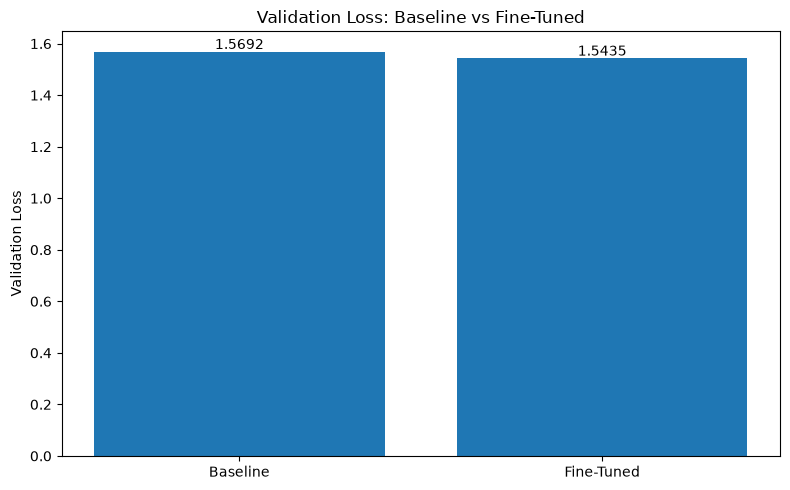

In [14]:
# ============================================================
# BASELINE VS FINE-TUNED VALIDATION LOSS
# ============================================================

labels = ["Baseline", "Fine-Tuned"]

loss_values = [
    baseline["validation_loss"],
    fine_tuned["validation_loss"]
]

plt.figure(figsize=(8, 5))

plt.bar(labels, loss_values)

plt.title("Validation Loss: Baseline vs Fine-Tuned")
plt.ylabel("Validation Loss")

for i, value in enumerate(loss_values):
    plt.text(
        i,
        value + 0.01,
        f"{value:.4f}",
        ha="center"
    )

plt.tight_layout()
plt.show()

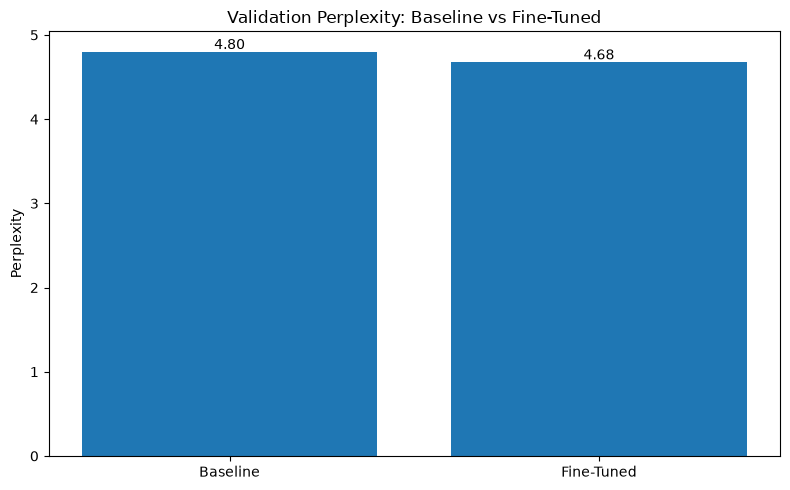

In [15]:
# ============================================================
# BASELINE VS FINE-TUNED PERPLEXITY
# ============================================================

perplexity_values = [
    baseline["validation_perplexity"],
    fine_tuned["validation_perplexity"]
]

plt.figure(figsize=(8, 5))

plt.bar(labels, perplexity_values)

plt.title("Validation Perplexity: Baseline vs Fine-Tuned")
plt.ylabel("Perplexity")

for i, value in enumerate(perplexity_values):
    plt.text(
        i,
        value + 0.03,
        f"{value:.2f}",
        ha="center"
    )

plt.tight_layout()
plt.show()

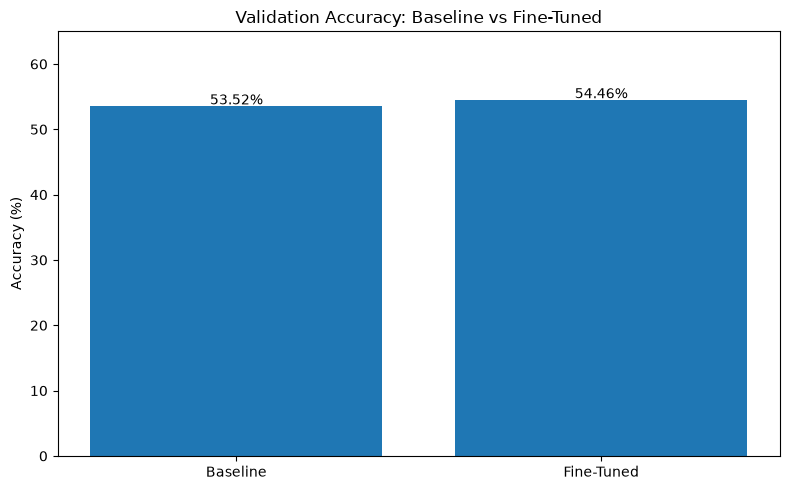

In [16]:
# ============================================================
# BASELINE VS FINE-TUNED ACCURACY
# ============================================================

accuracy_values = [
    baseline["validation_accuracy"] * 100,
    fine_tuned["validation_accuracy"] * 100
]

plt.figure(figsize=(8, 5))

plt.bar(labels, accuracy_values)

plt.title("Validation Accuracy: Baseline vs Fine-Tuned")
plt.ylabel("Accuracy (%)")

for i, value in enumerate(accuracy_values):
    plt.text(
        i,
        value + 0.3,
        f"{value:.2f}%",
        ha="center"
    )

plt.ylim(0, 65)

plt.tight_layout()
plt.show()

In [17]:
# ============================================================
# LOAD SAVED EVALUATION RESULTS
# ============================================================

import json

with open("../models/baseline_evaluation.json", "r") as file:
    baseline = json.load(file)

print("Baseline results loaded:")
print(baseline)

Baseline results loaded:
{'parameters': 3221567, 'training_loss': 1.3509242272377013, 'validation_loss': 1.5692376387119293, 'training_perplexity': 3.8609923164462248, 'validation_perplexity': 4.80298518771129, 'training_accuracy': 0.581708984375, 'validation_accuracy': 0.5351708984375}


In [18]:
# ============================================================
# FINE-TUNED RESULTS
# ============================================================

fine_tuned = {
    "validation_loss": 1.5435,
    "validation_perplexity": 4.68,
    "validation_accuracy": 0.5446
}

print("Fine-tuned results loaded:")
print(fine_tuned)

Fine-tuned results loaded:
{'validation_loss': 1.5435, 'validation_perplexity': 4.68, 'validation_accuracy': 0.5446}


In [19]:
# ============================================================
# PERFORMANCE IMPROVEMENT
# ============================================================

loss_change = (
    (baseline["validation_loss"] - fine_tuned["validation_loss"])
    / baseline["validation_loss"]
) * 100

perplexity_change = (
    (baseline["validation_perplexity"] - fine_tuned["validation_perplexity"])
    / baseline["validation_perplexity"]
) * 100

accuracy_change = (
    fine_tuned["validation_accuracy"]
    - baseline["validation_accuracy"]
) * 100

print("=" * 60)
print("PERFORMANCE CHANGES")
print("=" * 60)

print(f"Validation Loss improvement       : {loss_change:.2f}%")
print(f"Validation Perplexity improvement : {perplexity_change:.2f}%")
print(f"Accuracy improvement              : +{accuracy_change:.2f} percentage points")

PERFORMANCE CHANGES
Validation Loss improvement       : 1.64%
Validation Perplexity improvement : 2.56%
Accuracy improvement              : +0.94 percentage points


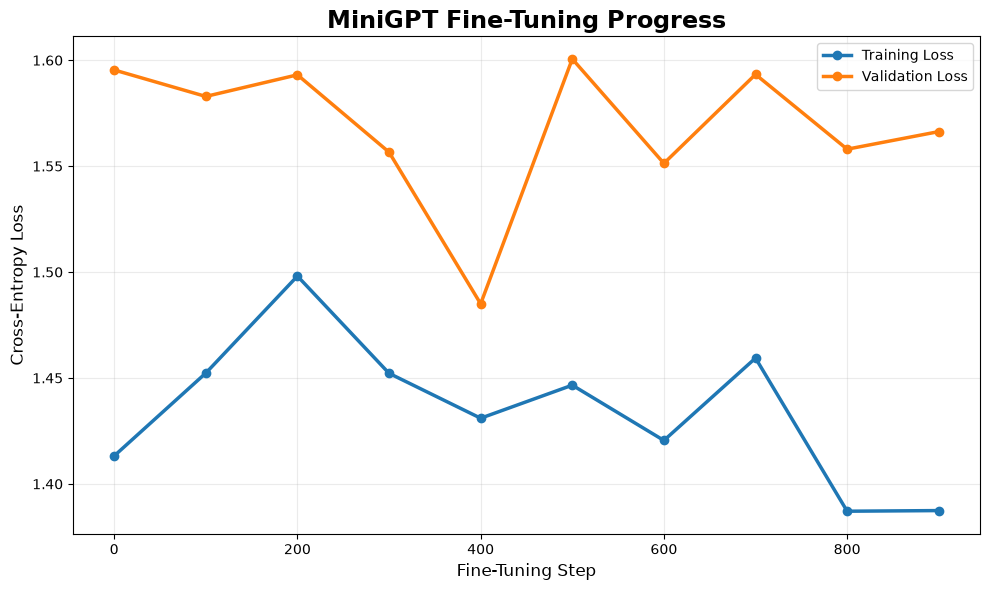

In [20]:
import matplotlib.pyplot as plt

# Actual values logged during fine-tuning
steps = [0, 100, 200, 300, 400, 500, 600, 700, 800, 900]

train_loss = [
    1.4132,
    1.4523,
    1.4981,
    1.4522,
    1.4310,
    1.4466,
    1.4205,
    1.4594,
    1.3871,
    1.3874
]

val_loss = [
    1.5954,
    1.5829,
    1.5931,
    1.5566,
    1.4850,
    1.6006,
    1.5513,
    1.5933,
    1.5580,
    1.5663
]

plt.figure(figsize=(10, 6))

plt.plot(
    steps,
    train_loss,
    marker="o",
    linewidth=2.5,
    label="Training Loss"
)

plt.plot(
    steps,
    val_loss,
    marker="o",
    linewidth=2.5,
    label="Validation Loss"
)

plt.title(
    "MiniGPT Fine-Tuning Progress",
    fontsize=17,
    fontweight="bold"
)

plt.xlabel("Fine-Tuning Step", fontsize=12)
plt.ylabel("Cross-Entropy Loss", fontsize=12)

plt.grid(True, alpha=0.25)
plt.legend()

plt.tight_layout()

plt.savefig(
    "minigpt_finetuning_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

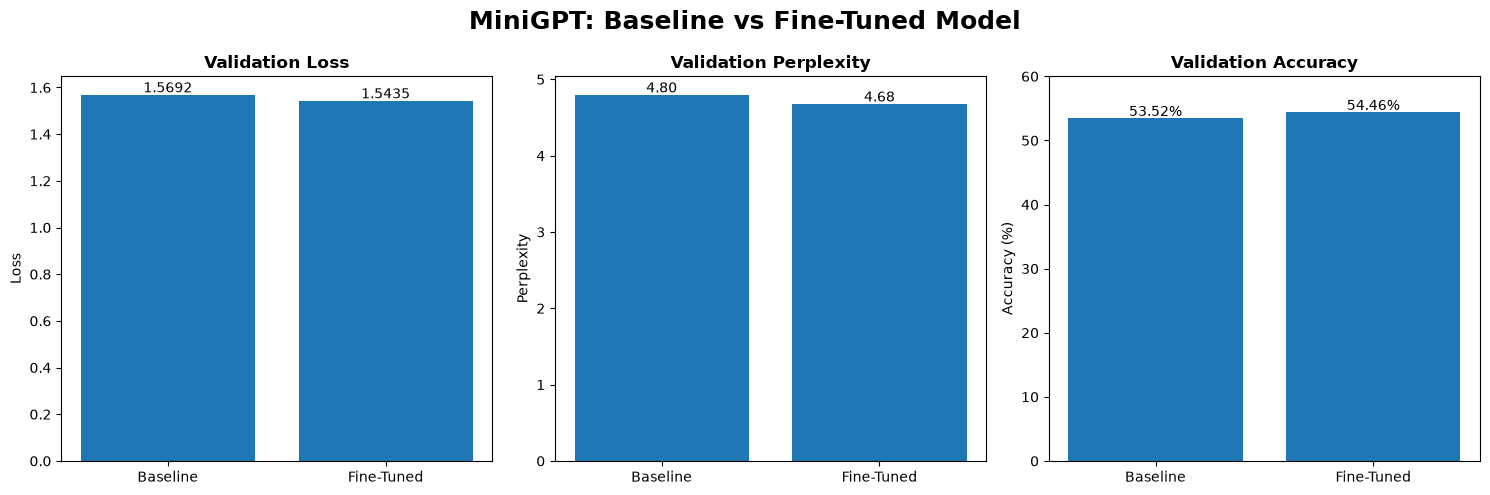

In [21]:
import matplotlib.pyplot as plt

metrics = ["Validation Loss", "Perplexity", "Accuracy"]

baseline_values = [
    1.5692,
    4.80,
    53.52
]

finetuned_values = [
    1.5435,
    4.68,
    54.46
]

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# -------------------------------------------------
# Validation Loss
# -------------------------------------------------

axes[0].bar(
    ["Baseline", "Fine-Tuned"],
    [baseline_values[0], finetuned_values[0]]
)

axes[0].set_title(
    "Validation Loss",
    fontweight="bold"
)

axes[0].set_ylabel("Loss")

for i, value in enumerate(
    [baseline_values[0], finetuned_values[0]]
):
    axes[0].text(
        i,
        value + 0.01,
        f"{value:.4f}",
        ha="center"
    )

# -------------------------------------------------
# Perplexity
# -------------------------------------------------

axes[1].bar(
    ["Baseline", "Fine-Tuned"],
    [baseline_values[1], finetuned_values[1]]
)

axes[1].set_title(
    "Validation Perplexity",
    fontweight="bold"
)

axes[1].set_ylabel("Perplexity")

for i, value in enumerate(
    [baseline_values[1], finetuned_values[1]]
):
    axes[1].text(
        i,
        value + 0.03,
        f"{value:.2f}",
        ha="center"
    )

# -------------------------------------------------
# Accuracy
# -------------------------------------------------

axes[2].bar(
    ["Baseline", "Fine-Tuned"],
    [baseline_values[2], finetuned_values[2]]
)

axes[2].set_title(
    "Validation Accuracy",
    fontweight="bold"
)

axes[2].set_ylabel("Accuracy (%)")

for i, value in enumerate(
    [baseline_values[2], finetuned_values[2]]
):
    axes[2].text(
        i,
        value + 0.3,
        f"{value:.2f}%",
        ha="center"
    )

axes[2].set_ylim(0, 60)

fig.suptitle(
    "MiniGPT: Baseline vs Fine-Tuned Model",
    fontsize=18,
    fontweight="bold"
)

plt.tight_layout()

plt.savefig(
    "minigpt_baseline_vs_finetuned.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

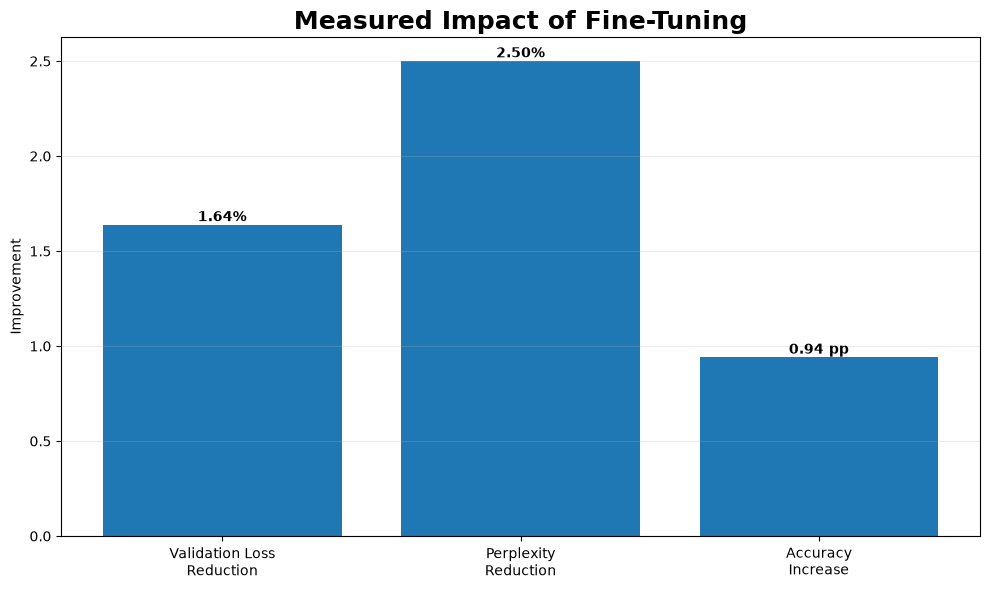

Loss reduction       : 1.64%
Perplexity reduction : 2.50%
Accuracy increase    : +0.94 percentage points


In [22]:
import matplotlib.pyplot as plt

loss_improvement = (
    (1.5692 - 1.5435) / 1.5692
) * 100

perplexity_improvement = (
    (4.80 - 4.68) / 4.80
) * 100

accuracy_gain = 54.46 - 53.52

labels = [
    "Validation Loss\nReduction",
    "Perplexity\nReduction",
    "Accuracy\nIncrease"
]

values = [
    loss_improvement,
    perplexity_improvement,
    accuracy_gain
]

plt.figure(figsize=(10, 6))

bars = plt.bar(
    labels,
    values
)

plt.title(
    "Measured Impact of Fine-Tuning",
    fontsize=18,
    fontweight="bold"
)

plt.ylabel("Improvement")

for bar, value, suffix in zip(
    bars,
    values,
    ["%", "%", " pp"]
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.02,
        f"{value:.2f}{suffix}",
        ha="center",
        fontweight="bold"
    )

plt.grid(
    axis="y",
    alpha=0.25
)

plt.tight_layout()

plt.savefig(
    "minigpt_finetuning_impact.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(f"Loss reduction       : {loss_improvement:.2f}%")
print(f"Perplexity reduction : {perplexity_improvement:.2f}%")
print(f"Accuracy increase    : +{accuracy_gain:.2f} percentage points")

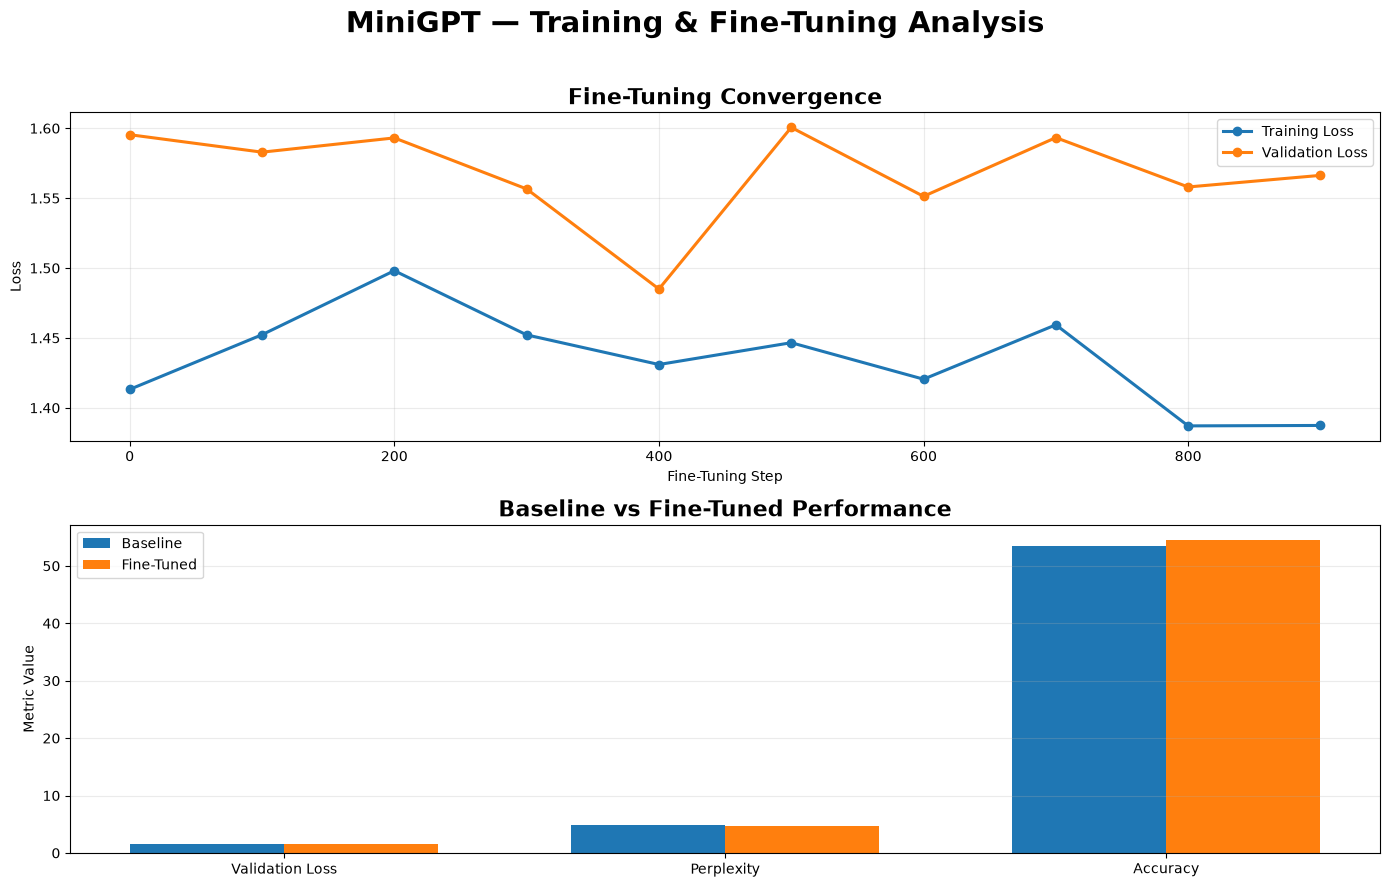

In [23]:
import matplotlib.pyplot as plt

fig = plt.figure(figsize=(14, 9))

# ============================================================
# TOP — Fine-tuning curve
# ============================================================

ax1 = plt.subplot(2, 1, 1)

ax1.plot(
    steps,
    train_loss,
    marker="o",
    linewidth=2.2,
    label="Training Loss"
)

ax1.plot(
    steps,
    val_loss,
    marker="o",
    linewidth=2.2,
    label="Validation Loss"
)

ax1.set_title(
    "Fine-Tuning Convergence",
    fontsize=16,
    fontweight="bold"
)

ax1.set_xlabel("Fine-Tuning Step")
ax1.set_ylabel("Loss")

ax1.grid(True, alpha=0.25)
ax1.legend()

# ============================================================
# BOTTOM — Metrics
# ============================================================

ax2 = plt.subplot(2, 1, 2)

metric_labels = [
    "Validation Loss",
    "Perplexity",
    "Accuracy"
]

baseline = [
    1.5692,
    4.80,
    53.52
]

finetuned = [
    1.5435,
    4.68,
    54.46
]

x = range(len(metric_labels))

width = 0.35

ax2.bar(
    [i - width/2 for i in x],
    baseline,
    width,
    label="Baseline"
)

ax2.bar(
    [i + width/2 for i in x],
    finetuned,
    width,
    label="Fine-Tuned"
)

ax2.set_xticks(list(x))
ax2.set_xticklabels(metric_labels)

ax2.set_title(
    "Baseline vs Fine-Tuned Performance",
    fontsize=16,
    fontweight="bold"
)

ax2.set_ylabel("Metric Value")
ax2.legend()

ax2.grid(
    axis="y",
    alpha=0.25
)

fig.suptitle(
    "MiniGPT — Training & Fine-Tuning Analysis",
    fontsize=21,
    fontweight="bold"
)

plt.tight_layout(rect=[0, 0, 1, 0.96])

plt.savefig(
    "minigpt_linkedin_analysis.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()